# Praktikum SKLearn SVM untuk Klasifikasi
**Platform:** Visual Studio Code (VS Code)  
**Algoritma:** Support Vector Machine (SVM)  
**Dataset:** `diabetes.csv` (Pima Indians Diabetes)

**Persiapan folder:** Simpan notebook ini dan file `diabetes.csv` di folder yang sama.  
**Tujuan:** Identifikasi dataset, preprocessing, pembagian data, pelatihan SVM, prediksi, dan evaluasi.

## 0. Instalasi Library
Jalankan perintah berikut di Terminal VS Code (cukup sekali, bukan di sel Python):

```bash
python -m pip install numpy pandas matplotlib seaborn scikit-learn jupyter ipykernel
```

Buka notebook ini di VS Code, pilih kernel Python, lalu jalankan sel dari atas ke bawah.

## 1. Import Library

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Membaca Dataset dari Folder Lokal
Pastikan `diabetes.csv` berada satu folder dengan notebook ini. Jika nama atau lokasinya berbeda, ubah nilai `file_path`.

In [6]:
file_path = "diabetes.csv"

if not os.path.exists(file_path):
    notebook_dir = r"E:\Dataset Machine Learning"
    candidate_path = os.path.join(notebook_dir, file_path)

    if os.path.isfile(candidate_path):
        file_path = candidate_path
    else:
        raise FileNotFoundError(
            f"File '{file_path}' tidak ditemukan. "
            f"Letakkan diabetes.csv di '{notebook_dir}' atau sesuaikan file_path."
        )

df = pd.read_csv(file_path)
print("Dataset berhasil dibaca.")
display(df.head())

Dataset berhasil dibaca.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Identifikasi Dataset

In [7]:
print("Ukuran dataset (baris, kolom):", df.shape)
print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe())

print("\nJumlah nilai kosong:")
display(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

Ukuran dataset (baris, kolom): (768, 9)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistik deskriptif:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Jumlah nilai kosong:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Jumlah data duplikat: 0


## 4. Preprocessing Data
Untuk dataset Pima Indians Diabetes, nilai 0 pada Glucose, BloodPressure, SkinThickness, Insulin, dan BMI umumnya diperlakukan sebagai nilai tidak valid/missing pada latihan ini. Ganti dengan median. Pastikan asumsi ini sesuai dengan dataset yang digunakan.

In [8]:
kolom_nol = [
    kolom for kolom in
    ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
    if kolom in df.columns
]

for kolom in kolom_nol:
    df[kolom] = df[kolom].replace(0, np.nan)
    df[kolom] = df[kolom].fillna(df[kolom].median())

df = df.drop_duplicates()

print("Nilai kosong setelah preprocessing:")
display(df.isnull().sum())
print("Ukuran data setelah preprocessing:", df.shape)

Nilai kosong setelah preprocessing:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Ukuran data setelah preprocessing: (768, 9)


## 5. Menentukan Fitur (X) dan Target (y)

In [9]:
if 'Outcome' not in df.columns:
    raise ValueError("Kolom 'Outcome' tidak ditemukan. Periksa nama kolom dataset.")

X = df.drop(columns=['Outcome'])
y = df['Outcome']

print("Kolom fitur:", list(X.columns))
print("\nDistribusi label:")
display(y.value_counts().sort_index())

Kolom fitur: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Distribusi label:


Outcome
0    500
1    268
Name: count, dtype: int64

## 6. Membagi Data Training dan Testing
Data dibagi 80% untuk training dan 20% untuk testing. `stratify=y` mempertahankan proporsi kelas.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 614
Jumlah data testing: 154


## 7. Normalisasi Data
Scaler dipelajari dari data training saja untuk menghindari data leakage.

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Normalisasi selesai.")

Normalisasi selesai.


## 8. Membuat dan Melatih Model SVM

In [12]:
model = SVC(kernel='linear', C=1.0)
model.fit(X_train_scaled, y_train)

print("Model SVM berhasil dilatih.")

Model SVM berhasil dilatih.


## 9. Melakukan Prediksi

In [13]:
y_pred = model.predict(X_test_scaled)

hasil = pd.DataFrame({
    'Aktual': y_test.to_numpy(),
    'Prediksi': y_pred
})
display(hasil.head(10))

,Aktual,Prediksi
0,0,1
1,0,0
2,0,0
3,1,0
4,0,0
5,0,0
6,1,0
7,1,1
8,0,0
9,0,1


## 10. Menghitung Akurasi

In [14]:
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi model SVM: {akurasi * 100:.2f}%")

Akurasi model SVM: 70.13%


## 11. Confusion Matrix

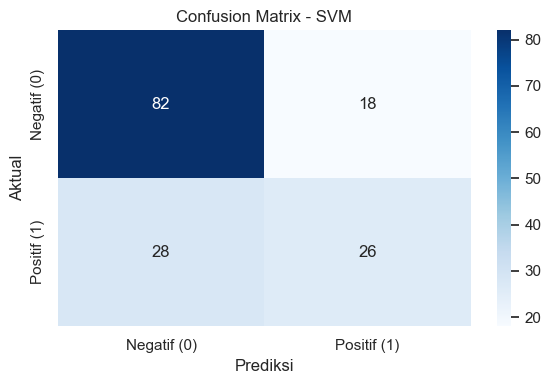

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negatif (0)', 'Positif (1)'],
    yticklabels=['Negatif (0)', 'Positif (1)']
)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - SVM')
plt.tight_layout()
plt.show()

## 12. Classification Report

In [16]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Negatif Diabetes (0)', 'Positif Diabetes (1)'],
    zero_division=0
))

                      precision    recall  f1-score   support

Negatif Diabetes (0)       0.75      0.82      0.78       100
Positif Diabetes (1)       0.59      0.48      0.53        54

            accuracy                           0.70       154
           macro avg       0.67      0.65      0.66       154
        weighted avg       0.69      0.70      0.69       154



## 13. Kesimpulan
Model SVM digunakan untuk mengklasifikasikan data menjadi dua kelas berdasarkan fitur dataset. Evaluasi dilakukan menggunakan akurasi, confusion matrix, precision, recall, dan F1-score.

**Lengkapi setelah menjalankan notebook:** tuliskan nilai akurasi yang diperoleh dan jelaskan hasil precision, recall, serta F1-score.

*Catatan: hasil model untuk latihan ini bukan alat diagnosis medis.*